# Face-Aware Tripwire Surveillance

This lab studies how a tracked boundary crossing can trigger a face comparison in recorded video. Each confirmed entry is classified as a match, a non-match, or unverified. A clear non-match produces one JPEG for that visit.

| Member | Roll number | Contribution |
|---|---|---|
| Guna | cs24b2043 | Face detection, enrollment, embeddings and decision rules |
| Susan | cs23b20xx | Demo integration, outputs, verification and documentation |
| Vivek | cs2310xx | Person detection, tracking, region geometry and crossing state |

Use **Runtime → Run all** in Colab with **CPU** and **Enroll demo** selected and **Upload photo** disabled. The default run downloads the public footage and pretrained model files.

## 1. Runtime setup

The setup cell checks the required Ultralytics, OpenCV, LAP and FFmpeg package versions. It configures the working directory `face_aware_tripwire_runtime/` for cached assets and generated files. LAP supports track association, and FFmpeg encodes the final video for playback.

In [1]:
import importlib.metadata as metadata
import os
import subprocess
import sys
from pathlib import Path

packages = {
    "ultralytics": "8.3.225",
    "opencv-python": "4.11.0.86",
    "lap": "0.5.12",
    "imageio-ffmpeg": "0.6.0",
}
install = []
for name, required in packages.items():
    try:
        current = metadata.version(name)
    except metadata.PackageNotFoundError:
        current = None
    if current != required:
        install.append(f"{name}=={required}")
if install:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *install], check=True)

ROOT = Path.cwd() / "face_aware_tripwire_runtime"
ROOT.mkdir(exist_ok=True)
config = ROOT / "settings"
config.mkdir(exist_ok=True)
os.environ["YOLO_CONFIG_DIR"] = str(config)
os.environ["YOLO_VERBOSE"] = "false"

import hashlib
import json
import math
import platform
import time
from collections import Counter, deque
from dataclasses import dataclass, field

import cv2
import imageio_ffmpeg
import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import FileLink, Image, Video, display
from ultralytics import YOLO, settings

settings.update({"sync": False})
cv2.setNumThreads(2)
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f"Python {platform.python_version()} | OpenCV {cv2.__version__} | "
      f"PyTorch {torch.__version__} | Ultralytics {metadata.version('ultralytics')}")

Python 3.11.5 | OpenCV 4.11.0 | PyTorch 2.10.0+cpu | Ultralytics 8.3.225


## 2. Experimental settings

The region spans **(285, 290) to (405, 431)** in the 768 × 432 source at 12 fps. The demo concatenates the half-open intervals below in playback order. The reference is frame **996 (83.00 s)**, selected from a separate 82.00–84.00 s window of the same recording. **Person A** is a pseudonym.

| Clip | Source interval (s) | Purpose |
|---|---:|---|
| A | 74.50–81.00 | Observe the enrolled person entering |
| B | 3.25–19.83 | Observe a different person entering, waiting and exiting |
| A, derived | 74.50–80.00 | Repeat A with the face area covered for the face stage |

The settings cell also defines the crossing confirmation length, the face sampling window and the decision thresholds used below.

In [2]:
# @title Demo settings
DEVICE = "cpu" # @param ["cpu", "0"]
ENROLL_DEMO = True # @param {type:"boolean"}
UPLOAD_PHOTO = False # @param {type:"boolean"}
UPLOAD_ALIAS = "Guest" # @param {type:"string"}

REGION = (285, 290, 405, 431)  # x1, y1, x2, y2 in the native 768 x 432 frame
SEGMENTS = [
    ("A / original", 894, 972, False),       # 74.50-81.00 s
    ("B / original", 39, 238, False),        # 03.25-19.83 s
    ("A / derived occlusion", 894, 960, True),  # 74.50-80.00 s
]
REFERENCE_FRAME = 996  # 83.00 s, outside all evaluation windows
REFERENCE_WINDOW = (984, 1008)  # separate 82.00-84.00 s enrollment window

CONFIRM_FRAMES = 3
BOUNDARY_PAD = 5
SAMPLE_EVERY = 2
PRE_FRAMES = 8
POST_FRAMES = 10
MIN_FACE_PIXELS = 34
MIN_FACE_SHARPNESS = 15
MIN_OBSERVATIONS = 3
MATCH_AT = .48
NON_MATCH_AT = .30
ALIAS_MARGIN = .08
if DEVICE != "cpu" and not torch.cuda.is_available():
    raise RuntimeError("Select CPU or connect a Colab GPU runtime.")

## 3. Footage and model downloads

The asset list contains the Intel clip, YOLO11n weights, and the YuNet and SFace ONNX files. The download function validates each file against a SHA-256 digest and accepts cached files that pass the same check.

In [3]:
ASSETS = {
    "intel.mp4": (
        "d88ab9aa03634f66f8815db3dc940e1cdd80b098440effb20882e814fd206bf5",
        "https://cdn.jsdelivr.net/gh/intel-iot-devkit/sample-videos@master/face-demographics-walking-and-pause.mp4",
        "https://raw.githubusercontent.com/intel-iot-devkit/sample-videos/master/face-demographics-walking-and-pause.mp4",
    ),
    "yolo11n.pt": (
        "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
        "https://huggingface.co/Ultralytics/YOLO11/resolve/main/yolo11n.pt",
        "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt",
    ),
    "yunet.onnx": (
        "8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4",
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
        "https://huggingface.co/opencv/face_detection_yunet/resolve/main/face_detection_yunet_2023mar.onnx",
    ),
    "sface.onnx": (
        "0ba9fbfa01b5270c96627c4ef784da859931e02f04419c829e83484087c34e79",
        "https://huggingface.co/opencv/face_recognition_sface/resolve/main/face_recognition_sface_2021dec.onnx",
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx",
    ),
}


def fetch(name):
    digest, *urls = ASSETS[name]
    path = ROOT / name
    if path.is_file():
        with path.open("rb") as current:
            if hashlib.file_digest(current, "sha256").hexdigest() == digest:
                print(f"{name} | verified session cache")
                return path
    partial = path.with_suffix(path.suffix + ".part")
    errors = []
    for url in urls:
        try:
            checksum = hashlib.sha256()
            with requests.get(url, stream=True, timeout=(10, 25)) as response:
                response.raise_for_status()
                with partial.open("wb") as output:
                    for chunk in response.iter_content(chunk_size=1 << 18):
                        checksum.update(chunk)
                        output.write(chunk)
            if checksum.hexdigest() != digest:
                raise ValueError("SHA-256 mismatch")
            partial.replace(path)
            print(f"{name} | downloaded and verified")
            return path
        except (requests.RequestException, ValueError) as error:
            errors.append(f"{url}: {error}")
        finally:
            partial.unlink(missing_ok=True)
    raise RuntimeError(f"Download failed for {name}\n" + "\n".join(errors))


VIDEO_PATH, YOLO_PATH, YUNET_PATH, SFACE_PATH = (fetch(name) for name in ASSETS)

intel.mp4 | downloaded and verified


yolo11n.pt | downloaded and verified


yunet.onnx | downloaded and verified


sface.onnx | downloaded and verified


## 4. Person tracking and crossing state

YOLO11n supplies person boxes, and ByteTrack associates detections across frames. The bottom-center of each box approximates the person's position. A five-pixel band around the region edges reduces transitions caused by box jitter. The image bottom coincides with the region bottom, so that edge is excluded from the crossing test.

`Crossing.update` establishes a baseline and confirms a new side after three consecutive observations beyond the band. A missing frame or a point in the band interrupts the candidate streak. Only a confirmed change creates a crossing event. `TrackState` stores the current crossing state, recent embeddings and any pending entry.

[Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11/) · [ByteTrack paper](https://arxiv.org/abs/2110.06864)

In [4]:
@dataclass
class Crossing:
    stable: bool | None = None
    candidate: bool | None = None
    streak: int = 0
    last_frame: int = -2

    def update(self, side, frame_number):
        if side is None or frame_number != self.last_frame + 1:
            self.candidate, self.streak = None, 0
        self.last_frame = frame_number
        if side is None or side == self.stable:
            self.candidate, self.streak = None, 0
            return None
        if side != self.candidate:
            self.candidate, self.streak = side, 0
        self.streak += 1
        if self.streak < CONFIRM_FRAMES:
            return None
        previous = self.stable
        self.stable = side
        self.candidate, self.streak = None, 0
        if previous is None:
            return None
        return "Entry" if side else "Exit"


@dataclass
class PendingEntry:
    event: dict
    frame: np.ndarray
    box: tuple
    foot: tuple
    deadline: int
    samples: list


@dataclass
class TrackState:
    crossing: Crossing = field(default_factory=Crossing)
    observations: deque = field(default_factory=deque)
    pending: PendingEntry | None = None
    decision: "Decision | None" = None
    inside_frames: int = 0


def foot_side(foot, region, width, height):
    x, y = foot
    x1, y1, x2, y2 = region
    # A region edge at the image limit cannot be crossed in the visible frame.
    signed = min(x-x1 if x1 else width, x2-x if x2 < width-1 else width,
                 y-y1 if y1 else height, y2-y if y2 < height-1 else height)
    if signed >= BOUNDARY_PAD:
        return True
    if signed <= -BOUNDARY_PAD:
        return False
    return None


def valid_region(region, width, height):
    x1, y1, x2, y2 = region
    if not (0 <= x1 < x2 < width and 0 <= y1 < y2 < height
            and min(x2-x1, y2-y1) > 2 * BOUNDARY_PAD):
        raise ValueError(f"Region {region} is invalid for {width} x {height}.")


def clipped_box(raw, width, height):
    x1, y1, x2, y2 = (round(v) for v in raw)
    return (max(0, x1), max(0, y1), min(width, x2), min(height, y2))


COLORS = {"Match": (62, 220, 92), "Non-match": (65, 75, 250),
          "Unverified": (36, 191, 253), "Neutral": (235, 231, 219)}
REGION_COLOR = (246, 203, 64)


def label(image, text, x, y, color, scale=.62):
    height, width = image.shape[:2]
    (tw, th), baseline = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 1)
    x = max(0, min(x, width - tw - 12))
    y = max(th + 7, min(y, height - baseline - 6))
    cv2.rectangle(image, (x, y-th-6), (x+tw+10, y+baseline+4), (19, 24, 29), -1)
    cv2.putText(image, text, (x+5, y), cv2.FONT_HERSHEY_SIMPLEX,
                scale, color, 1, cv2.LINE_AA)


def draw_region(image, region):
    x1, y1, x2, y2 = region
    cv2.rectangle(image, (x1, y1), (x2, y2), REGION_COLOR, 2, cv2.LINE_AA)
    label(image, "TRIPWIRE REGION", x1, y1-7, REGION_COLOR)


def draw_track(image, box, foot, track_id, status, color):
    x1, y1, x2, y2 = box
    cv2.rectangle(image, (x1, y1), (x2-1, y2-1), color, 2, cv2.LINE_AA)
    cv2.circle(image, (foot[0], min(foot[1], image.shape[0]-1)), 5, color, -1)
    label(image, f"ID {track_id} | {status}", x1, y1-8, color)


def stamp(image, segment, video_time, source_time):
    label(image, f"{segment} | Video {video_time:.2f}s | Source {source_time:.2f}s",
          10, 30, COLORS["Neutral"])

## 5. Face observation and comparison

YuNet must find one face at confidence **0.80** or higher. For tracked people, the search uses the upper **55%** of the box and requires a centered detection. The face must measure at least **34 pixels** in both dimensions and have grayscale Laplacian variance of at least **15**. SFace aligns the crop using five landmarks and returns a unit-normalized embedding. The dot product of two unit embeddings is their cosine similarity.

| Decision | Evidence from the same track |
|---|---|
| Match | At least three usable samples. The best alias has median cosine ≥ 0.48. At least two thirds of samples reach 0.48 for that alias and lead any rival by ≥ 0.08. |
| Non-match | At least three usable samples. At least two thirds score ≤ 0.30 against every enrolled alias. |
| Unverified | Too few usable samples, an empty gallery, or scores that fail the decision rules above. |

The interval between the cutoffs brackets the **0.363** SFace cosine reference reported for LFW by OpenCV. These are demonstration settings. [OpenCV face recognition tutorial](https://docs.opencv.org/4.x/d0/dd4/tutorial_dnn_face.html)

In [5]:
@dataclass(frozen=True)
class FaceObservation:
    embedding: np.ndarray
    aligned: np.ndarray
    row: np.ndarray


class FaceEncoder:
    def __init__(self, detector_path, recognizer_path):
        self.detector = cv2.FaceDetectorYN.create(
            str(detector_path), "", (320, 320), .80, .30, 20
        )
        self.recognizer = cv2.FaceRecognizerSF.create(str(recognizer_path), "")

    def observe(self, image, person_box=None):
        if person_box is not None:
            x1, y1, x2, y2 = person_box
            head_bottom = y1 + round((y2 - y1) * .55)
            image = image[y1:head_bottom, x1:x2]
        height, width = image.shape[:2]
        if min(height, width) < MIN_FACE_PIXELS:
            return None

        self.detector.setInputSize((width, height))
        _, faces = self.detector.detect(image)
        if faces is None or len(faces) != 1:
            return None
        face = faces[0]
        x, y, w, h = face[:4]
        if min(w, h) < MIN_FACE_PIXELS:
            return None
        if person_box is not None and not .19 * width <= x + w / 2 <= .81 * width:
            return None
        patch = image[max(0, int(y)):min(height, round(y+h)),
                      max(0, int(x)):min(width, round(x+w))]
        if min(patch.shape[:2]) < MIN_FACE_PIXELS:
            return None
        gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
        if cv2.Laplacian(gray, cv2.CV_64F).var() < MIN_FACE_SHARPNESS:
            return None
        aligned = self.recognizer.alignCrop(image, face)
        vector = self.recognizer.feature(aligned).ravel()
        length = np.linalg.norm(vector)
        if not np.isfinite(length) or length <= 0:
            return None
        return FaceObservation(vector / length, aligned, face)


@dataclass(frozen=True)
class Decision:
    state: str
    alias: str = ""
    cosine: float | None = None
    count: int = 0
    reason: str = ""

    @property
    def label(self):
        return f"Match: {self.alias}" if self.state == "Match" else self.state


def classify(vectors, gallery):
    count = len(vectors)
    if count < MIN_OBSERVATIONS:
        return Decision("Unverified", count=count, reason="Too few usable faces")
    if not gallery:
        return Decision("Unverified", count=count, reason="No enrollment")
    aliases = list(gallery)
    scores = np.clip(np.stack(vectors) @ np.stack(list(gallery.values())).T, -1, 1)
    medians = np.median(scores, axis=0)
    best = int(np.argmax(medians))
    score = float(medians[best])
    needed = math.ceil(2 * count / 3)
    rivals = np.delete(scores, best, axis=1)
    best_rows = scores[:, best]
    margins = best_rows - rivals.max(axis=1) if rivals.shape[1] else np.full(count, 2.)
    if score >= MATCH_AT and np.count_nonzero(
        (best_rows >= MATCH_AT) & (margins >= ALIAS_MARGIN)
    ) >= needed:
        return Decision("Match", aliases[best], score, count, "Consistent enrolled match")
    if np.count_nonzero(scores.max(axis=1) <= NON_MATCH_AT) >= needed:
        return Decision("Non-match", cosine=score, count=count, reason="Below cutoff for every alias")
    return Decision("Unverified", cosine=score, count=count, reason="Ambiguous or inconsistent scores")

## 6. Reference enrollment

This cell creates the face encoder and enrolls the reference in an in-memory gallery. It displays the aligned crop used for the embedding and shows the region on a source frame.

To try a different gallery, enable **Upload photo**, enter a distinct alias and rerun from the settings cell. Use a consented, unobstructed portrait with one face.

Enrolled Person A | aligned SFace input


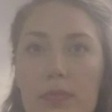

Tripwire rectangle (285, 290, 405, 431) | Source 12 fps


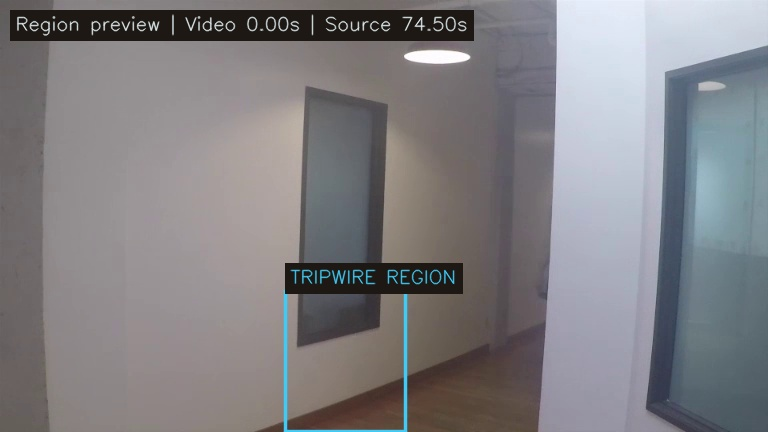

In [6]:
def read_source_frame(number):
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    try:
        if not cap.set(cv2.CAP_PROP_POS_FRAMES, number):
            raise RuntimeError(f"Could not seek to frame {number}.")
        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f"Could not decode frame {number}.")
        return frame, cap.get(cv2.CAP_PROP_FPS)
    finally:
        cap.release()


def show_jpeg(bgr):
    ok, encoded = cv2.imencode(".jpg", bgr)
    if not ok:
        raise RuntimeError("Could not encode preview.")
    display(Image(data=encoded.tobytes()))


def enroll(alias, image):
    alias = alias.strip()
    if not (1 <= len(alias) <= 24 and alias.isascii() and alias.isprintable()):
        raise ValueError("Use a printable alias with 1-24 ASCII characters.")
    if alias in gallery:
        raise ValueError(f"The alias {alias!r} is already enrolled.")
    observation = encoder.observe(image)
    if observation is None:
        raise ValueError("Use a sharp photo with one unobstructed face at least 34 px wide and high.")
    gallery[alias] = observation.embedding
    print(f"Enrolled {alias} | aligned SFace input")
    show_jpeg(observation.aligned)


encoder = FaceEncoder(YUNET_PATH, SFACE_PATH)
gallery = {}
if ENROLL_DEMO:
    reference, _ = read_source_frame(REFERENCE_FRAME)
    enroll("Person A", reference)

def enroll_uploaded_photo(alias):
    from tempfile import TemporaryDirectory

    try:
        from google.colab import files as colab_files
    except ImportError as error:
        raise RuntimeError("The photo picker requires Google Colab.") from error
    with TemporaryDirectory(dir=ROOT) as folder:
        photo_path = Path(folder) / "portrait"
        colab_files.upload_file(str(photo_path))
        photo = cv2.imread(str(photo_path))
        if photo is None:
            raise ValueError("Could not decode the uploaded photo.")
        enroll(alias, photo)


if UPLOAD_PHOTO:
    enroll_uploaded_photo(UPLOAD_ALIAS)

preview, source_fps = read_source_frame(SEGMENTS[0][1])
valid_region(REGION, preview.shape[1], preview.shape[0])
draw_region(preview, REGION)
stamp(preview, "Region preview", 0, SEGMENTS[0][1]/source_fps)
print(f"Tripwire rectangle {REGION} | Source {source_fps:g} fps")
show_jpeg(preview)

## 7. Frame processing and alert generation

`run_demo` starts a new tracker at each cut and prefixes each tracker ID with the clip number. In the derived replay, it covers the top 41% of each tracked box after person tracking and before face detection.

A confirmed entry stores the event and its frame. The classifier uses embeddings sampled every other frame, up to eight frames before and ten after confirmation, from that track. The decision stays with the track until a confirmed exit clears it. For a clear non-match, the code annotates the saved entry frame and writes one JPEG. The video combines the rendered frames into a silent H.264 MP4.

In [7]:
def finish_entry(state, region, alerts):
    entry = state.pending
    decision = classify(entry.samples, gallery)
    state.decision, state.pending = decision, None
    event = entry.event
    event.update(decision=decision.label, state=decision.state,
                 cosine=decision.cosine, observations=decision.count, reason=decision.reason)
    if decision.state != "Non-match":
        return
    image = entry.frame
    draw_region(image, region)
    draw_track(image, entry.box, entry.foot, event["track_id"], decision.label, COLORS["Non-match"])
    stamp(image, event["segment"], event["video_s"], event["source_s"])
    path = alerts / f'alert_{event["video_frame"]:05d}_{event["track_id"]}.jpg'
    if not cv2.imwrite(str(path), image, [cv2.IMWRITE_JPEG_QUALITY, 92]):
        raise OSError(f"Could not save {path}.")
    event["alert"] = str(path)


def obscure_head(frame, box):
    x1, y1, x2, y2 = box
    bottom = y1 + round(.41 * (y2-y1))
    frame[y1:bottom, x1:x2] = (54, 58, 62)


def run_demo():
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    raw_path = ROOT / "annotated_intermediate.mp4"
    stage_path = ROOT / "annotated_staged.mp4"
    video_path = ROOT / "annotated_tripwire.mp4"
    alerts = ROOT / "alerts"
    alerts.mkdir(exist_ok=True)
    for stale in alerts.glob("alert_*.jpg"):
        stale.unlink()
    video_path.unlink(missing_ok=True)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width, height = (int(cap.get(key)) for key in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    writer = None
    events, observed_tracks = [], []
    video_frame = 0
    start = time.perf_counter()
    try:
        if not cap.isOpened() or not fps:
            raise RuntimeError("Could not open the source video.")
        valid_region(REGION, width, height)
        writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
        if not writer.isOpened():
            raise RuntimeError("Could not start the intermediate MP4 writer.")
        for clip_id, (segment, first, stop, obscure) in enumerate(SEGMENTS, 1):
            if not 0 <= first < stop <= frame_count or not cap.set(cv2.CAP_PROP_POS_FRAMES, first):
                raise ValueError(f"Invalid source frame range for {segment}.")
            # A cut is a discontinuity. Start a fresh ByteTrack instance at each cut.
            model = YOLO(str(YOLO_PATH))
            states = {}
            for number in range(first, stop):
                ok, raw = cap.read()
                if not ok:
                    raise RuntimeError(f"Could not decode source frame {number}.")
                result = model.track(raw, tracker="bytetrack.yaml", persist=True, classes=[0],
                                     conf=.15, imgsz=640, device=DEVICE, verbose=False)[0]
                boxes = result.boxes
                tracks = []
                if boxes.id is not None:
                    for tid, coordinates in zip(boxes.id.int().tolist(), boxes.xyxy.tolist()):
                        box = clipped_box(coordinates, width, height)
                        if box[2] > box[0] and box[3] > box[1]:
                            tracks.append((f"{clip_id}.{tid}", box))

                # The derived test applies this edit after person tracking and before face detection.
                frame = raw.copy()
                if obscure:
                    for _, box in tracks:
                        obscure_head(frame, box)
                overlay = frame.copy()
                draw_region(overlay, REGION)
                stamp(overlay, segment, video_frame/fps, number/fps)
                for track_id, box in tracks:
                    state = states.setdefault(track_id, TrackState())
                    x1, _, x2, y2 = box
                    foot = ((x1+x2)//2, min(y2-1, height-1))
                    side = foot_side(foot, REGION, width, height)
                    crossing = state.crossing.update(side, number)
                    while state.observations and state.observations[0][0] < number - PRE_FRAMES:
                        state.observations.popleft()
                    if number % SAMPLE_EVERY == 0 and (state.crossing.stable is not True
                                                        or crossing == "Entry" or state.pending):
                        observation = encoder.observe(frame, box)
                        if observation is not None:
                            state.observations.append((number, observation.embedding))
                            if state.pending and number <= state.pending.deadline:
                                state.pending.samples.append(observation.embedding)
                    if state.crossing.stable is True:
                        state.inside_frames += 1
                    if crossing:
                        event = dict(video_frame=video_frame, video_s=video_frame/fps, source_s=number/fps,
                                     segment=segment, track_id=track_id, crossing=crossing,
                                     decision="Rearmed", state="Exit", cosine=None, observations=None,
                                     reason="Confirmed outside", alert="")
                        events.append(event)
                        if crossing == "Entry":
                            state.pending = PendingEntry(
                                event, frame.copy(), box, foot, number + POST_FRAMES,
                                [vector for _, vector in state.observations]
                            )
                        else:
                            if state.pending:
                                finish_entry(state, REGION, alerts)
                            state.decision = None
                            state.observations.clear()
                    if state.pending and number >= state.pending.deadline:
                        finish_entry(state, REGION, alerts)

                    if state.pending:
                        status, color = "Checking face", COLORS["Unverified"]
                    elif state.decision and state.crossing.stable is True:
                        status, color = state.decision.label, COLORS[state.decision.state]
                    else:
                        status = "Inside" if state.crossing.stable else "Outside"
                        if crossing == "Exit":
                            status = "Exit / rearmed"
                        color = COLORS["Neutral"]
                    draw_track(overlay, box, foot, track_id, status, color)

                # Finish an entry on time even if a track disappears during its observation window.
                for state in states.values():
                    if state.pending and number >= state.pending.deadline:
                        finish_entry(state, REGION, alerts)
                writer.write(overlay)
                video_frame += 1
            for track_id, state in states.items():
                if state.pending:
                    finish_entry(state, REGION, alerts)
                observed_tracks.append(dict(segment=segment, track_id=track_id,
                                            inside_frames=state.inside_frames))
            print(f"Processed {segment} ({stop-first} frames).")
    finally:
        cap.release()
        if writer is not None:
            writer.release()

    ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
    try:
        subprocess.run([ffmpeg, "-v", "error", "-y", "-i", str(raw_path), "-an",
                        "-c:v", "libx264", "-preset", "fast", "-crf", "23", "-pix_fmt", "yuv420p",
                        "-movflags", "+faststart", str(stage_path)], check=True, capture_output=True)
        stage_path.replace(video_path)
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(exc.stderr.decode(errors="replace")) from exc
    finally:
        raw_path.unlink(missing_ok=True)
        stage_path.unlink(missing_ok=True)
    elapsed = time.perf_counter() - start
    metrics = dict(frames=video_frame, fps=video_frame/elapsed, seconds=elapsed, source_fps=fps,
                   tracks=observed_tracks, events=events)
    return video_path, metrics

## 8. Recorded outputs

This cell runs the demo, displays the MP4 and event table, and writes `run_summary.json`. **Video (s)** is time in the concatenated playback. **Source (s)** is time in the original footage. The table and JPEG use the crossing confirmation time. The playback overlay displays the face decision after sampling ends.

Green denotes a match, red a clear non-match and amber an unverified entry. During the face observation window, the overlay reads **Checking face**.

Processed A / original (78 frames).


Processed B / original (199 frames).


Processed A / derived occlusion (66 frames).


343 frames | 37.4 s | 9.2 processed frames/s | cpu
3 entries, 1 exits, 1 alert JPEG(s)


,Video (s),Source (s),Segment,Track ID,Crossing,Decision,Cosine,Faces,Evidence
0,2.83,77.33,A / original,1.1,Entry,Match: Person A,0.571,7.0,Consistent enrolled match
1,8.92,5.67,B / original,2.1,Entry,Non-match,0.011,5.0,Below cutoff for every alias
2,22.17,18.92,B / original,2.1,Exit,Rearmed,—,—,Confirmed outside
3,25.92,77.33,A / derived occlusion,3.1,Entry,Unverified,—,0.0,Too few usable faces


Alert 1 | alert_00107_2.1.jpg


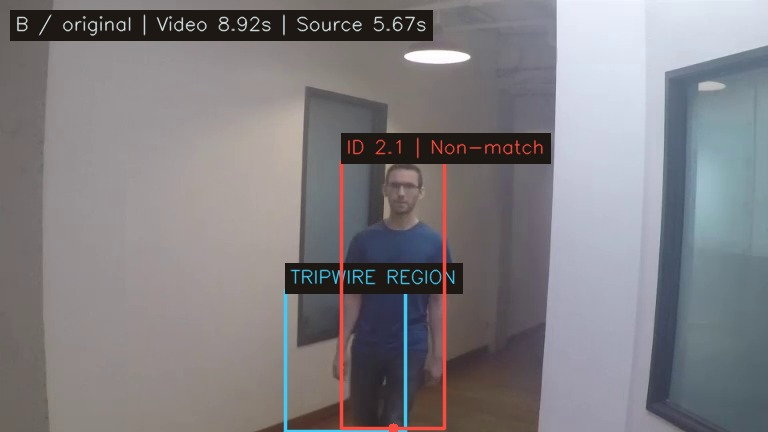

2065

In [8]:
video_path, metrics = run_demo()
events = metrics["events"]
counts = Counter(event["state"] for event in events)
alerts = [Path(event["alert"]) for event in events if event["alert"]]
print(f'{metrics["frames"]} frames | {metrics["seconds"]:.1f} s | '
      f'{metrics["fps"]:.1f} processed frames/s | {DEVICE}')
print(f'{sum(counts[k] for k in ("Match", "Non-match", "Unverified"))} entries, '
      f'{counts["Exit"]} exits, {len(alerts)} alert JPEG(s)')

display(Video(filename=str(video_path), embed=True, mimetype="video/mp4", width=768))
table = pd.DataFrame([
    {"Video (s)": round(e["video_s"], 2), "Source (s)": round(e["source_s"], 2),
     "Segment": e["segment"], "Track ID": e["track_id"], "Crossing": e["crossing"],
     "Decision": e["decision"], "Cosine": round(e["cosine"], 3) if e["cosine"] is not None else None,
     "Faces": e["observations"], "Evidence": e["reason"]}
    for e in events
])
display(table.fillna("—"))
for index, path in enumerate(alerts, 1):
    print(f"Alert {index} | {path.name}")
    display(Image(filename=str(path), width=768))

# Save the run summary beside the runtime video for repeatable measurement.
(ROOT / "run_summary.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

## 9. Download an alert

Set **Alert number** to the number shown above the corresponding JPEG and run this cell. The default of zero leaves the output displayed in the notebook.

In [9]:
# @title Download a JPEG alert
ALERT_NUMBER = 0 # @param {type:"integer"}
if ALERT_NUMBER:
    if not 1 <= ALERT_NUMBER <= len(alerts):
        raise ValueError(f"Choose a displayed alert number from 1 to {len(alerts)}.")
    selected = alerts[ALERT_NUMBER - 1]
    try:
        from google.colab import files as colab_files
    except ImportError:
        display(FileLink(selected.relative_to(Path.cwd()).as_posix()))
    else:
        colab_files.download(str(selected))

## 10. Verification

The default assertions check the three entry decisions, one alert JPEG, the non-matching track's dwell and exit, and the encoded frame count. A separate state test feeds known inside, outside and boundary observations to verify re-entry after a confirmed exit.

In [10]:
if ENROLL_DEMO and not UPLOAD_PHOTO:
    entries = [e for e in events if e["crossing"] == "Entry"]
    observed = [(e["segment"], e["state"]) for e in entries]
    expected = [("A / original", "Match"), ("B / original", "Non-match"),
                ("A / derived occlusion", "Unverified")]
    assert observed == expected, observed
    assert entries[0]["decision"] == "Match: Person A"
    assert entries[2]["observations"] < MIN_OBSERVATIONS
    red = entries[1]
    red_crossings = [e["crossing"] for e in events if e["track_id"] == red["track_id"]]
    assert red_crossings == ["Entry", "Exit"], red_crossings
    dwell = next(t["inside_frames"] for t in metrics["tracks"] if t["track_id"] == red["track_id"])
    assert dwell >= 2 * metrics["source_fps"]
    assert len(alerts) == 1 and alerts[0].is_file()
    assert len(list((ROOT / "alerts").glob("alert_*.jpg"))) == 1
    jpg = cv2.imread(str(alerts[0]))
    assert jpg is not None and jpg.shape[:2] == (432, 768)
    cap = cv2.VideoCapture(str(video_path))
    try:
        assert cap.isOpened() and int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) == metrics["frames"]
    finally:
        cap.release()
    print("Model checks passed: enrolled match, clear non-match, unreadable face, and one alert.")
    print(f'Red track {red["track_id"]}: {dwell} tracked inside frames, then one confirmed exit.')
else:
    print("Reference expectations apply with only the built-in enrollment.")

# Derived state-machine check using known sides, with no model input.
checker = Crossing()
sides = ([False] * CONFIRM_FRAMES + [True] * (CONFIRM_FRAMES + 6)
         + [None, False, None] + [False] * CONFIRM_FRAMES + [True] * CONFIRM_FRAMES)
transitions = [event for number, side in enumerate(sides)
               if (event := checker.update(side, number))]
assert transitions == ["Entry", "Exit", "Entry"], transitions
print("State-machine check passed: dwell and edge jitter suppress repeats, then exit permits re-entry.")

Model checks passed: enrolled match, clear non-match, unreadable face, and one alert.
Red track 2.1: 159 tracked inside frames, then one confirmed exit.
State-machine check passed: dwell and edge jitter suppress repeats, then exit permits re-entry.


## Results and limitations

The saved local CPU run processed **343 frames in 37.4 seconds (9.2 fps)**, including encoding. Person A's median cosine was **0.571** over seven usable samples. The other actor's was **0.011** over five. Track **2.1** remained inside for **159 observed frames** and generated one JPEG before exiting. The derived replay yielded zero usable faces and an unverified entry.

The reference and test clips come from the same recording. Camera angle, cropping, occlusion and ID switches can change crossing and face decisions. A follow-up evaluation should use independent footage and measure missed crossings, false alerts and the rate of unverified decisions.

## Acknowledgments

Intel IoT DevKit supplied the footage under CC BY 4.0. The demo uses excerpts, overlays and one labeled occlusion replay. [Source clip](https://github.com/intel-iot-devkit/sample-videos/blob/master/face-demographics-walking-and-pause.mp4) · [License](https://creativecommons.org/licenses/by/4.0/)

The pipeline uses pretrained YOLO11n, ByteTrack, and the OpenCV Zoo YuNet and SFace models. [YuNet model](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet) · [SFace model](https://github.com/opencv/opencv_zoo/tree/main/models/face_recognition_sface)